# Customer Churn Prediction & Retention Strategy

**Dataset:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/blastchar/telco-customer-churn): 7,043 telecom customers, 21 columns.
**Goal:** find which customers are most likely to leave, predict churn with a model, and turn the predictions into retention decisions.

**What this notebook covers**
1. **Probability analysis:** overall, conditional and joint churn probabilities, lift.
2. **Gaussian Naive Bayes implemented from scratch** (NumPy), evaluated with accuracy, precision, recall, F1, ROC/AUC and calibration, and compared with scikit-learn.
3. **Business decisions:** expected value of retention, risk/value segmentation, budget optimization, sensitivity analysis.

**Key results**
- Overall churn rate: **26.5%**
- Month-to-month + Fiber optic customers: **54.6%** churn, **lift 2.06**
- From-scratch Naive Bayes: **AUC 0.807**, recall **0.84**, accuracy 0.69 (same level as scikit-learn GaussianNB)
- With a 50,000 budget: target **166** customers for about **83,000** expected profit

## 1. Load and prepare the data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

df["Churn"] = (df["Churn"] == "Yes").astype(int)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 2. Exploratory probability analysis

### 2.1 Overall churn probability, P(Churn)

In [2]:
p_churn = df["Churn"].mean()
p_churn

np.float64(0.2653698707936959)

### 2.2 Conditional probabilities

In [3]:
p1 = df.loc[df["Contract"]=="Month-to-month", "Churn"].mean()
p1

np.float64(0.4270967741935484)

In [4]:
p2 = df.loc[df["tenure"] < 12, "Churn"].mean()
p2

np.float64(0.4828419526341228)

In [5]:
p3 = df.loc[df["InternetService"]=="Fiber optic", "Churn"].mean()
p3

np.float64(0.4189276485788114)

In [6]:
p4 = df.loc[df["PaymentMethod"]=="Electronic check", "Churn"].mean()
p4

np.float64(0.4528541226215645)

### 2.3 Joint probability and lift
Customers with a **Month-to-month** contract **and Fiber optic** internet, compared with the average customer.

In [7]:
mask = (df["Contract"]=="Month-to-month") & (df["InternetService"]=="Fiber optic")
p_joint = df.loc[mask, "Churn"].mean()
lift = p_joint / p_churn
p_joint, lift

(np.float64(0.5460526315789473), np.float64(2.057703950888457))

### 2.4 Feature comparison: contract type, senior citizens, paperless billing

In [8]:
df.groupby("Contract")["Churn"].mean().sort_values()

Contract
Two year          0.028319
One year          0.112695
Month-to-month    0.427097
Name: Churn, dtype: float64

In [9]:
df.groupby("SeniorCitizen")["Churn"].mean()

SeniorCitizen
0    0.236062
1    0.416813
Name: Churn, dtype: float64

In [10]:
paper = df.groupby("PaperlessBilling")["Churn"].mean()
diff = paper["Yes"] - paper["No"]
paper, diff

(PaperlessBilling
 No     0.163301
 Yes    0.335651
 Name: Churn, dtype: float64,
 np.float64(0.17235008738544225))

### 2.5 Top 5 most predictive categorical features
For each categorical feature: the largest absolute difference between a category's churn rate and the overall churn rate.

In [11]:
import matplotlib.pyplot as plt

categorical = df.select_dtypes(include="object").columns.drop(["customerID"], errors="ignore")

overall = p_churn
scores = {}

for col in categorical:
    rates = df.groupby(col)["Churn"].mean()
    scores[col] = (rates - overall).abs().max()

top5 = sorted(scores, key=scores.get, reverse=True)[:5]
top5

['Contract',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection']

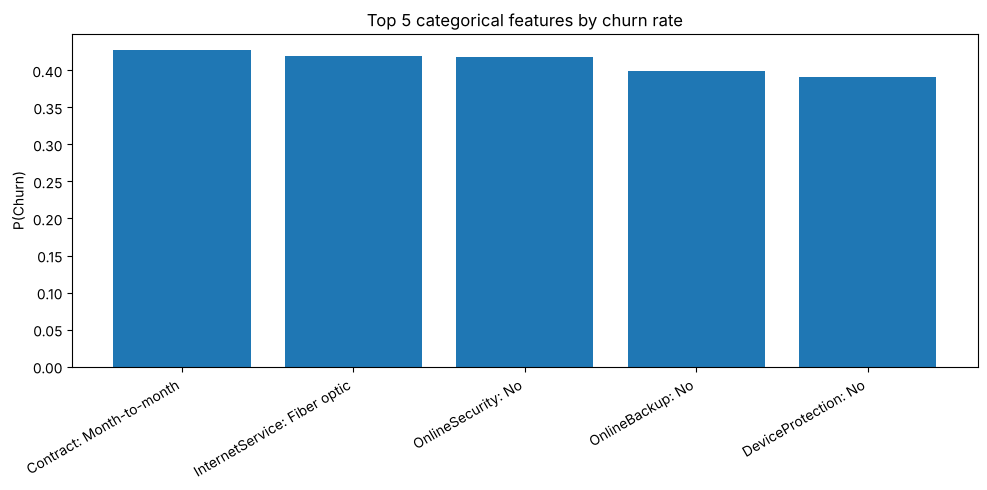

In [12]:
vals = []
labels = []
for col in top5:
    rates = df.groupby(col)["Churn"].mean()
    best_val = rates.sort_values(ascending=False).index[0]
    vals.append(rates.loc[best_val])
    labels.append(f"{col}: {best_val}")

plt.figure(figsize=(10,5))
plt.bar(labels, vals)
plt.xticks(rotation=30, ha="right")
plt.ylabel("P(Churn)")
plt.title("Top 5 categorical features by churn rate")
plt.tight_layout()
plt.show()

## 3. Gaussian Naive Bayes from scratch

### 3.1 Features, one-hot encoding and an 80/20 stratified split

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"]

X = pd.get_dummies(X, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 3.2 The classifier
- **Priors** P(class) from class frequencies.
- **Likelihood:** a normal distribution per feature and class (mean and variance from the training set).
- Log-probabilities for numerical stability, then softmax to turn them into class probabilities.

In [14]:
class GaussianNBFromScratch:
    def fit(self, X, y):
        self.classes_ = np.array(sorted(y.unique()))
        self.prior_ = {}
        self.mean_ = {}
        self.var_ = {}

        for c in self.classes_:
            Xc = X[y == c]
            self.prior_[c] = len(Xc) / len(X)
            self.mean_[c] = Xc.mean(axis=0)
            self.var_[c] = Xc.var(axis=0) + 1e-9  # avoid division by zero
        return self

    def _log_gaussian(self, X, mean, var):
        return -0.5 * (np.log(2*np.pi*var) + ((X-mean)**2)/var)

    def predict_proba(self, X):
        log_probs = []
        for c in self.classes_:
            log_prior = np.log(self.prior_[c])
            log_likelihood = self._log_gaussian(X, self.mean_[c], self.var_[c]).sum(axis=1)
            log_probs.append(log_prior + log_likelihood)

        log_probs = np.vstack(log_probs).T  # shape (n, 2)
        # softmax
        maxlog = log_probs.max(axis=1, keepdims=True)
        probs = np.exp(log_probs - maxlog)
        probs = probs / probs.sum(axis=1, keepdims=True)
        return probs

    def predict(self, X, threshold=0.5):
        proba = self.predict_proba(X)[:, 1]
        return (proba > threshold).astype(int)

### 3.3 Training and evaluation

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

model = GaussianNBFromScratch().fit(X_train, y_train)
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:,1]

acc = accuracy_score(y_test, pred)
prec = precision_score(y_test, pred)
rec = recall_score(y_test, pred)
f1 = f1_score(y_test, pred)
cm = confusion_matrix(y_test, pred)

acc, prec, rec, f1, cm

(0.694819020581973,
 0.45894428152492667,
 0.8368983957219251,
 0.5928030303030303,
 array([[666, 369],
        [ 61, 313]]))

### 3.4 ROC curve and AUC

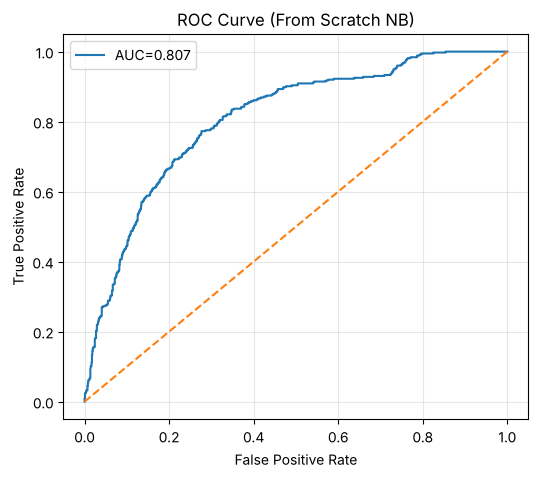

In [16]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test, proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (From Scratch NB)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3.5 Calibration plot

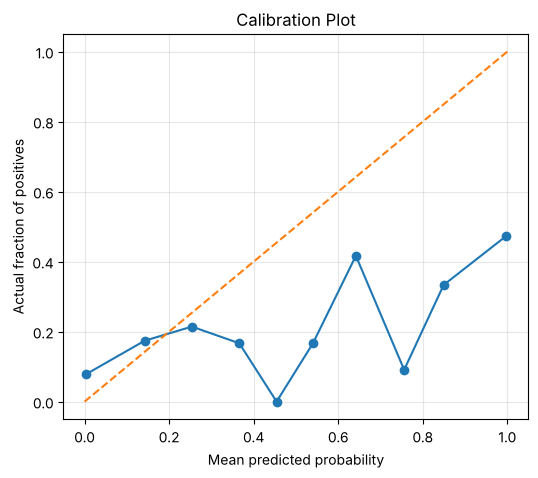

In [17]:
from sklearn.calibration import calibration_curve

frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10)

plt.figure(figsize=(6,5))
plt.plot(mean_pred, frac_pos, marker="o")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Actual fraction of positives")
plt.title("Calibration Plot")
plt.grid(True, alpha=0.3)
plt.show()

### 3.6 Comparison with scikit-learn GaussianNB

In [18]:
from sklearn.naive_bayes import GaussianNB

sk = GaussianNB()
sk.fit(X_train, y_train)
sk_proba = sk.predict_proba(X_test)[:,1]
sk_pred = (sk_proba > 0.5).astype(int)

accuracy_score(y_test, sk_pred), f1_score(y_test, sk_pred)

(0.6955287437899219, 0.5933649289099526)

## 4. From predictions to business decisions

Assumptions: customer lifetime value **CLV = 2000**, retention offer success rate **0.4**, campaign cost **300** per customer.

### 4.1 Maximum retention spend for a customer with P(churn) = 0.8

In [19]:
p = 0.8
CLV = 2000
success = 0.4
max_spend = p * CLV * success
max_spend

640.0

### 4.2 Expected profit when targeting customers with P(churn) > 0.5
EV = P(churn) × CLV × success − cost

In [20]:
cost = 300
ev = proba * CLV * success - cost
target_mask = proba > 0.5
total_profit = ev[target_mask].sum()
total_profit

np.float64(329324.78332662577)

### 4.3 Risk/value segmentation (2×2 matrix)
- **High Value:** MonthlyCharges > 70
- **High Risk:** P(churn) > 0.6

In [21]:
test_df = df.loc[X_test.index, ["MonthlyCharges"]].copy()
test_df["p_churn"] = proba

test_df["value"] = np.where(test_df["MonthlyCharges"] > 70, "High Value", "Low Value")
test_df["risk"]  = np.where(test_df["p_churn"] > 0.6, "High Risk", "Low Risk")
test_df["quadrant"] = test_df["value"] + " / " + test_df["risk"]

summary = test_df.groupby("quadrant").agg(
    customers=("p_churn","size"),
    expected_churn_loss=("p_churn", lambda s: (s*CLV).sum()),
    expected_net_gain=("p_churn", lambda s: (s*CLV*success - cost).sum()),
).sort_values("expected_net_gain", ascending=False)

summary

,customers,expected_churn_loss,expected_net_gain
quadrant,,,
High Value / High Risk,427,842175.379290,208770.151716
Low Value / High Risk,249,486154.097041,119761.638816
High Value / Low Risk,271,22540.738528,-72283.704589
Low Value / Low Risk,462,15842.302488,-132263.079005


### 4.4 Budget optimization (budget = 50,000)
Rank customers by expected value and target the most profitable ones until the budget runs out.

In [22]:
budget = 50000
test_df["ev"] = test_df["p_churn"] * CLV * success - cost

candidates = test_df.sort_values("ev", ascending=False)
candidates = candidates[candidates["ev"] > 0]  # profitable customers only

k = min(len(candidates), budget // cost)
picked = candidates.head(int(k))

num_targeted = len(picked)
total_expected_profit = picked["ev"].sum()
highrisk_covered = (picked["p_churn"] > 0.6).mean()

num_targeted, total_expected_profit, highrisk_covered

(166, np.float64(82999.99169866525), np.float64(1.0))

### 4.5 Sensitivity analysis

In [23]:
BASE_CLV, BASE_COST, BASE_SUCCESS = 2000, 300, 0.4

def calc_profit(proba, CLV, cost, success, threshold=0.5):
    ev = proba * CLV * success - cost
    mask = proba > threshold
    return mask.sum(), ev[mask].sum(), ev[mask].mean()

results = []
for name, CLV, cost, success in [
    ("Base", 2000, 300, 0.4),
    ("Success=0.2", 2000, 300, 0.2),
    ("Cost=500", 2000, 500, 0.4),
    ("CLV=1500", 1500, 300, 0.4),
]:
    n, profit, avg_ev = calc_profit(proba, CLV, cost, success)
    results.append([name, CLV, cost, success, n, profit, avg_ev])

pd.DataFrame(results, columns=[
    "scenario", "CLV", "cost", "success",
    "targeted_customers", "total_expected_profit", "avg_ev_per_customer"
])

,scenario,CLV,cost,success,targeted_customers,total_expected_profit,avg_ev_per_customer
0,Base,2000,300,0.4,682,329324.783327,482.880914
1,Success=0.2,2000,300,0.2,682,62362.391663,91.440457
2,Cost=500,2000,500,0.4,682,192924.783327,282.880914
3,CLV=1500,1500,300,0.4,682,195843.587495,287.160685


## 5. Conclusions

1. **Who churns:** 26.5% of customers leave overall. Risk is much higher for month-to-month contracts (42.7%), tenure under 12 months (48.3%), fiber optic internet (41.9%) and electronic check payment (45.3%). Month-to-month + Fiber optic is the riskiest combination: **54.6% churn, lift 2.06**. Two-year contracts churn the least (2.8%).
2. **Model:** the from-scratch Gaussian Naive Bayes reaches **AUC 0.807** and **recall 0.84**, so it catches most customers who actually leave. It matches scikit-learn's GaussianNB (accuracy about 0.69 for both). Precision is lower (0.46) and the calibration plot shows the probabilities are over-confident, so they should be calibrated before being used as exact values.
3. **Business:** targeting customers with P(churn) > 0.5 has a positive expected profit (about 329k on the test set). The **High Value / High Risk** segment gives the best return. With a 50,000 budget, the best 166 customers bring about 83,000 in expected profit.
4. **Sensitivity:** profit depends most on the offer's **success rate**: halving it from 0.4 to 0.2 cuts profit from about 329k to about 62k.

**Possible next steps:** try logistic regression or gradient boosting, calibrate the probabilities, and choose the decision threshold based on profit instead of a fixed 0.5.